# 03 · Roles

What kinds of IT jobs are posted, and how has the mix changed from 2020 to 2026?

**Method.** A role comes from the job *title* only. Each distinct title was labelled twice: by the ordered rules in `taxonomy.py`, and by Jev (step 06, one choice question over 18 role families, including "not IT" and "technician or engineer in a non-software field"). The final role is Jev's label when its confidence is at least 0.6, otherwise the rule's. Because only the title is used, a role trend does not depend on how long a source writes its descriptions; what can still distort it is *which sources were scraped*, so each trend is drawn for all sources and inside CareerBuilder (2020–2026) and LinkedIn (2023–2026).

Charts and aggregate tables are saved to `charts/` and `tables/`.

In [1]:
import sys
from pathlib import Path

# The notebook lives in notebooks/; the modules are one level up.
sys.path.insert(0, str(Path.cwd().parent))


import analysis as a
import roles as r

a.apply_style()
con = a.connect()
df = a.load_features(con)

## 1. How the labels were made

Where Jev is confident, how often does it pick the same role as the rule? The disagreements are listed so the choice of Jev as the final label can be judged.

In [2]:
agreement = r.agreement_by_rule(df)
a.save_table(agreement, "03-rule-vs-jev-agreement")
disagreements = r.top_disagreements(df, 30)
a.save_table(disagreements, "03-rule-vs-jev-disagreements")
print(
    f"{df.role_jev.notna().mean():.1%} of postings have a Jev label; "
    f"{(df.role_conf >= a.ROLE_CONFIDENCE).mean():.1%} at confidence >= {a.ROLE_CONFIDENCE}"
)
agreement

100.0% of postings have a Jev label; 86.5% at confidence >= 0.6


,rule_role,postings,agree
0,ai_ml,7721,84.3
1,ba_pm_product,192,12.5
2,backend,14936,83.1
3,data,10463,96.8
4,design,76,10.5
5,devops_cloud,6709,80.6
6,embedded_iot,2224,71.1
7,erp_consulting,1987,90.6
8,frontend,4236,81.5
9,fullstack,4733,96.4


In [3]:
disagreements

,title,rule,jev,postings
0,Quality Engineer,technical_non_software,qa_test,253
1,System Engineer,software_other,it_support_infra,197
2,Solution Architect,software_other,devops_cloud,121
3,Technical Support Engineer,technical_non_software,it_support_infra,116
4,Solutions Architect,software_other,devops_cloud,115
5,Chuyên Viên Kỹ Thuật,technical_non_software,software_other,83
6,Nhân Viên IT Phần Mềm,it_support_infra,software_other,74
7,IT Specialist,software_other,it_support_infra,72
8,Product Engineer,other,software_other,72
9,Kiến Trúc Sư Triển Khai,other,devops_cloud,63


## 2. The role mix

Postings per final role, 2020 to October 2026, all sources.

In [4]:
counts = r.role_counts(df)
a.save_table(counts, "03-role-counts")
counts

,role,postings,share
0,backend,13994,9.0
1,frontend,4544,2.9
2,fullstack,5404,3.5
3,mobile,3751,2.4
4,software_other,19566,12.5
5,devops_cloud,8378,5.4
6,data,12536,8.0
7,ai_ml,7422,4.8
8,qa_test,20878,13.4
9,security,4398,2.8


Share of each period's postings by role group. The left chart is every source; the right is CareerBuilder alone, where the title-based roles are not affected by description length.

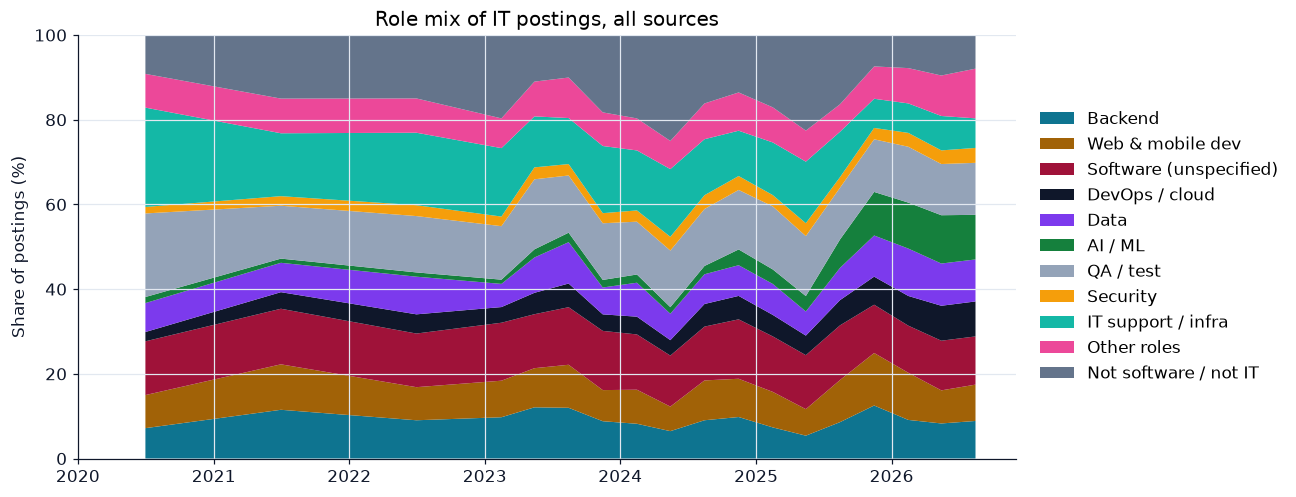

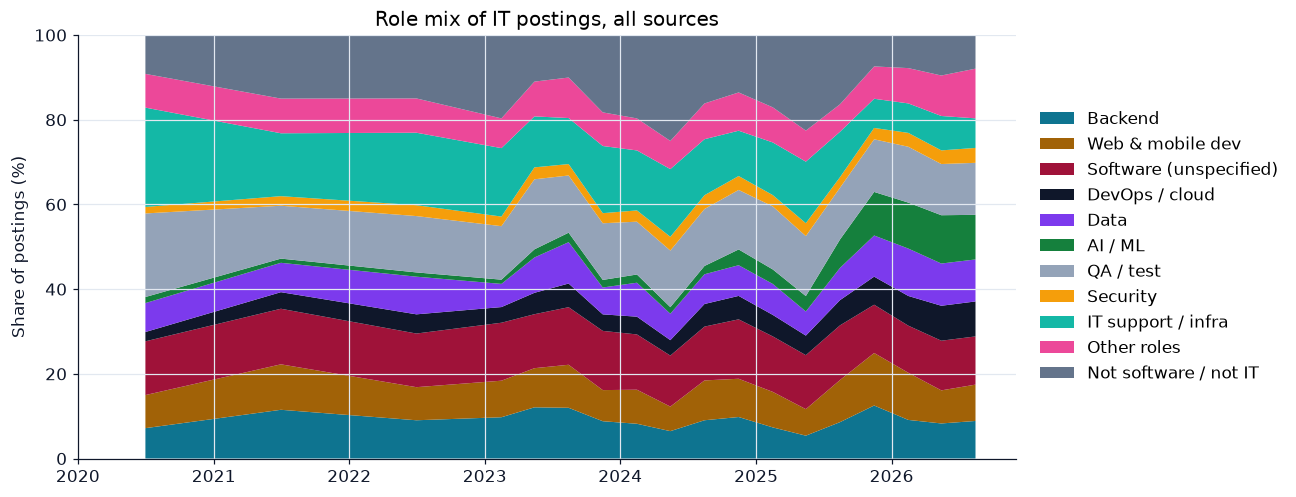

In [5]:
grouped = r.with_groups(df)
fig = a.stacked_share(grouped, "role_group", r.GROUP_ORDER, "Role mix of IT postings, all sources")
a.save_chart(fig, "03-role-mix-all-sources")
fig

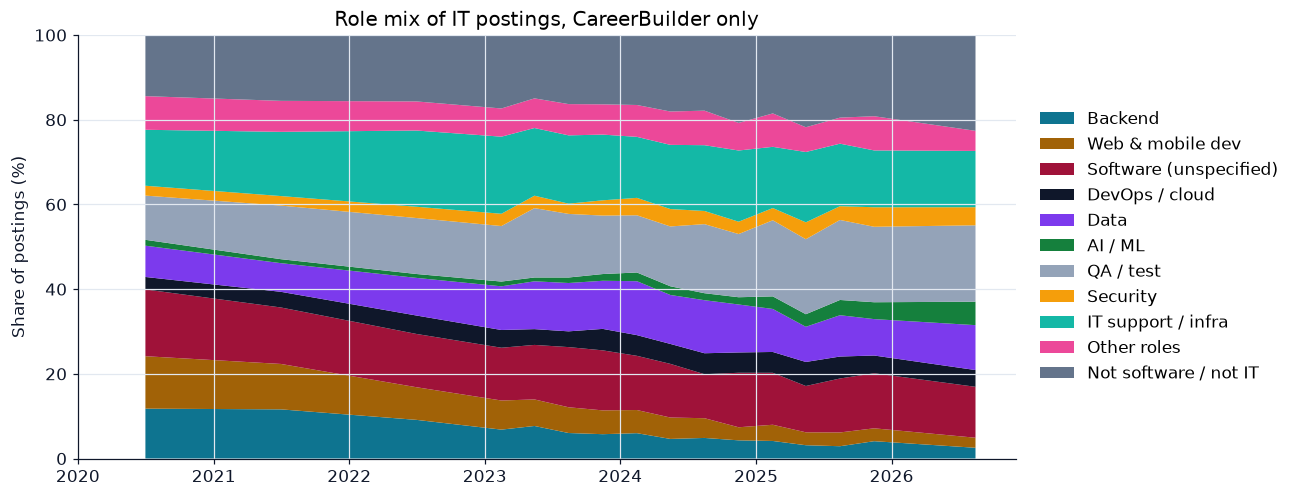

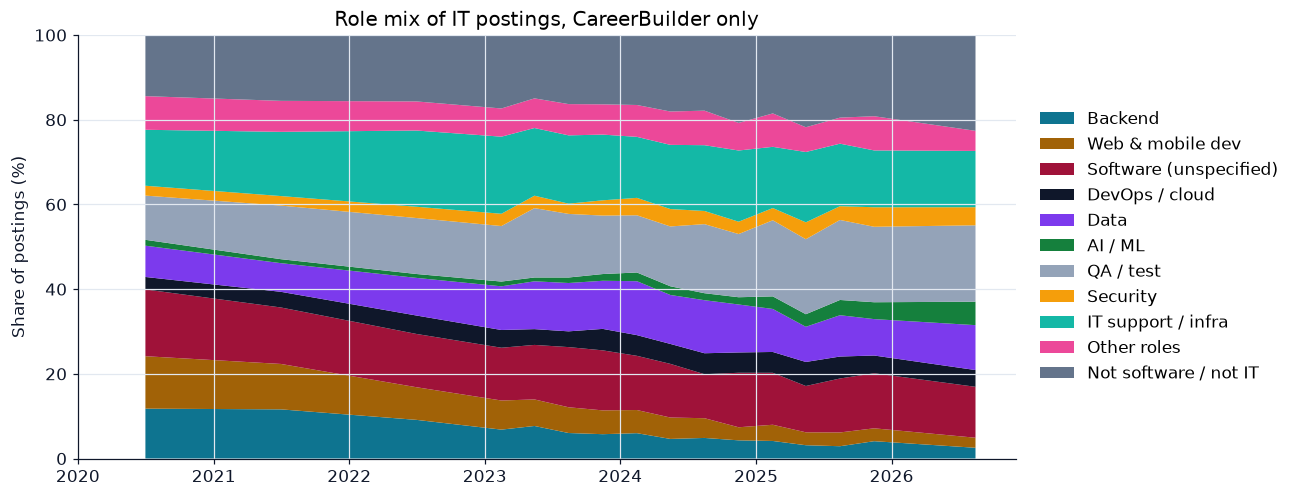

In [6]:
fig = a.stacked_share(
    grouped[grouped.source == "careerbuilder_vn"],
    "role_group",
    r.GROUP_ORDER,
    "Role mix of IT postings, CareerBuilder only",
)
a.save_chart(fig, "03-role-mix-careerbuilder")
fig

## 3. Role by role, with controls

Each panel shows one role's share of postings for all sources, CareerBuilder only and LinkedIn only. A role that moves the same way in all three lines is a market trend; a role that moves in only one is the source mix.

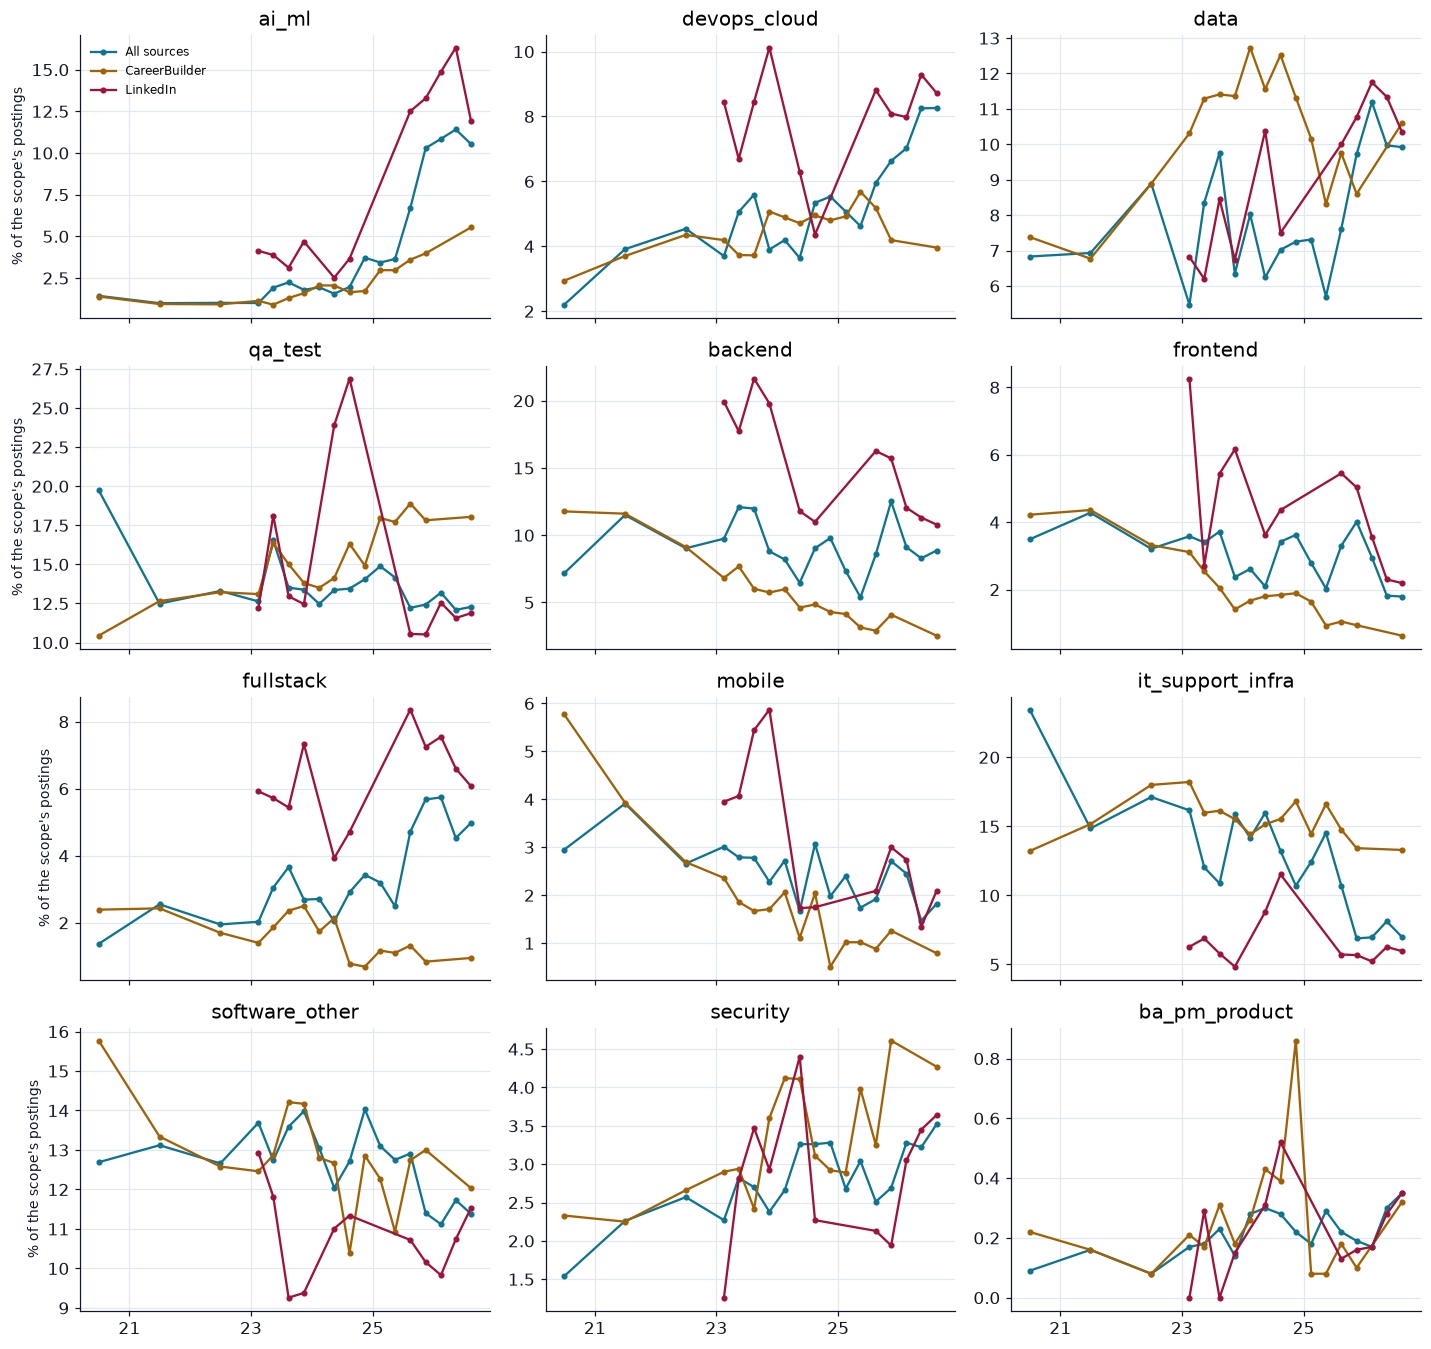

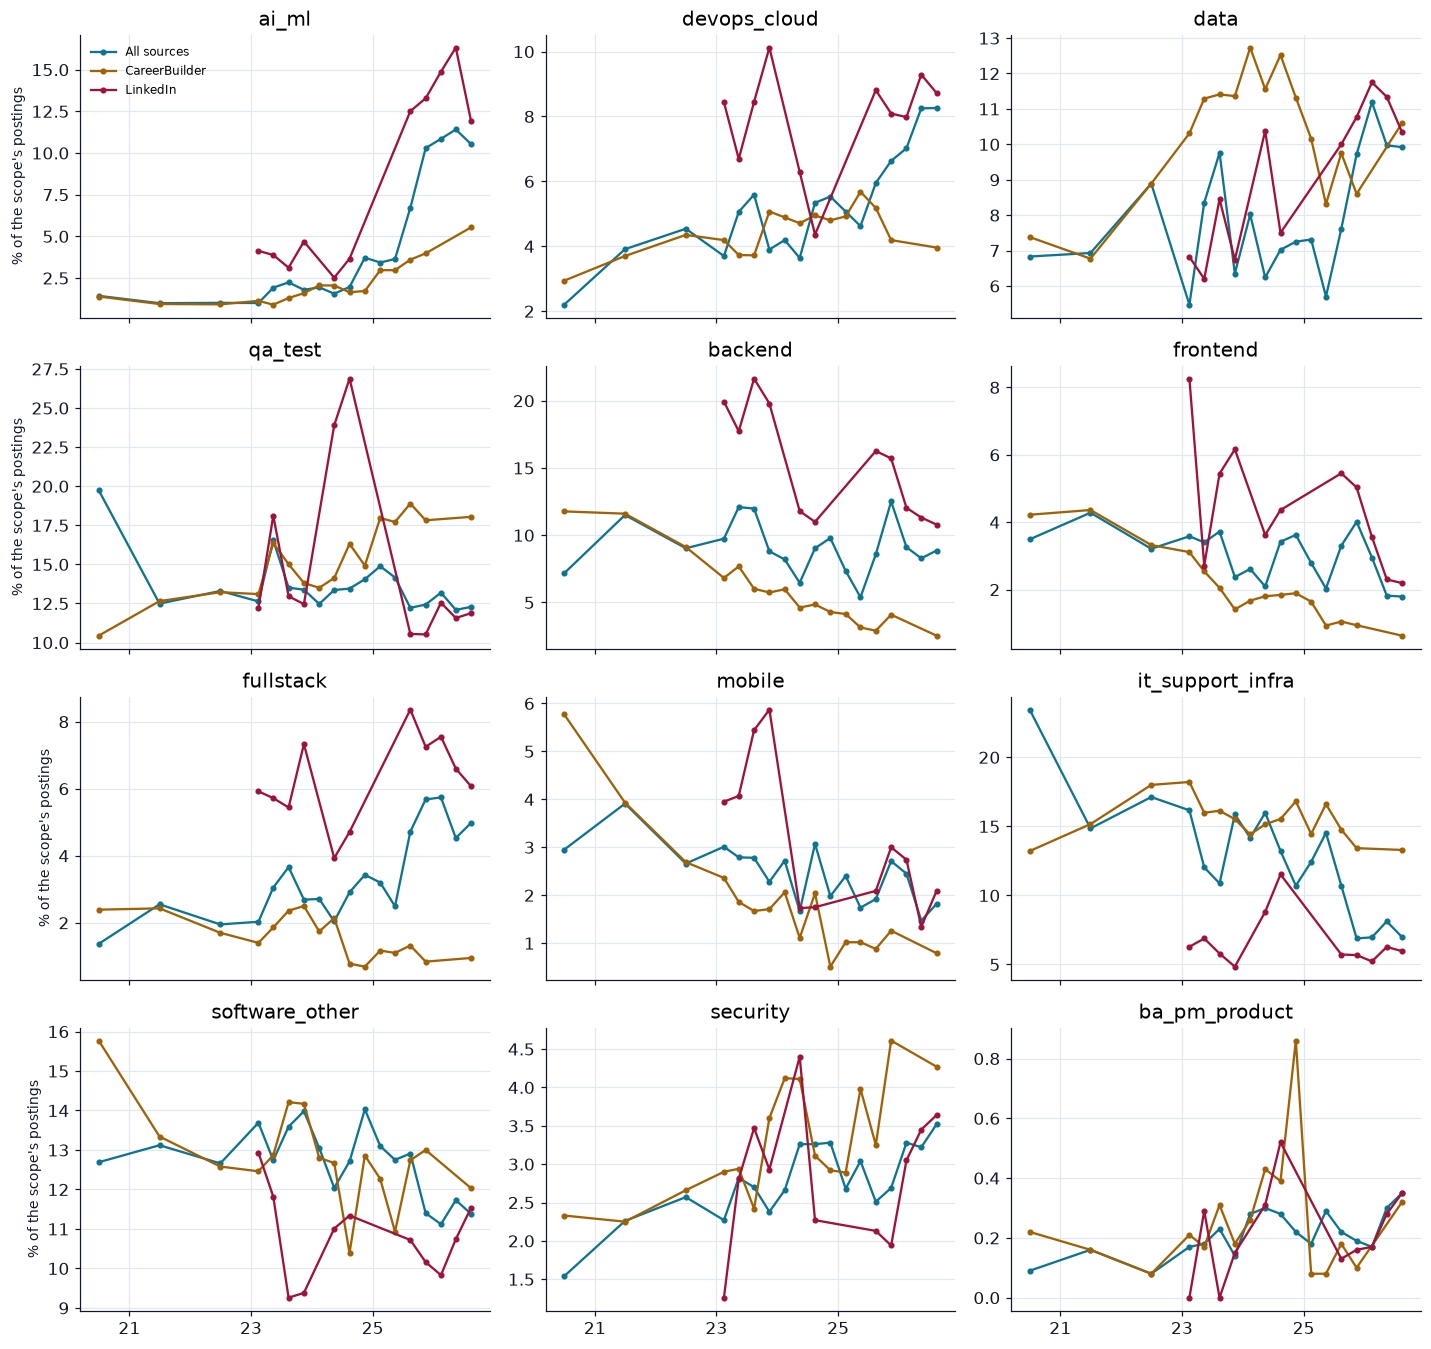

In [7]:
roles = [
    "ai_ml",
    "devops_cloud",
    "data",
    "qa_test",
    "backend",
    "frontend",
    "fullstack",
    "mobile",
    "it_support_infra",
    "software_other",
    "security",
    "ba_pm_product",
]
fig = r.chart_role_panels(df, roles)
a.save_chart(fig, "03-role-trends")
fig

## 4. How much of "IT" is not software

Jev labelled titles as tech from the title alone (step 04), and some of those are technicians or electrical, mechanical or automation engineers, or not IT at all. This is how large that group is, per year and source.

In [8]:
non_software = r.non_software_by_year(df)
a.save_table(non_software, "03-not-software-share")
non_software.pivot(index="year", columns="scope", values="technical_non_software").join(
    non_software.pivot(index="year", columns="scope", values="not_it"), rsuffix="_not_it"
)

/var/folders/gr/b7qhgnxs1tsdyx_r9qphz9740000gn/T/ipykernel_39022/2016255209.py:3: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  non_software.pivot(index="year", columns="scope", values="technical_non_software").join(


scope,All sources,CareerBuilder,LinkedIn,All sources_not_it,CareerBuilder_not_it,LinkedIn_not_it
year,,,,,,
2020,9.2,14.4,NaN,0.0,0.1,NaN
2021,15.0,15.5,NaN,0.0,0.0,NaN
2022,15.0,15.7,0.0,0.0,0.0,0.0
2023,16.5,16.2,2.4,0.0,0.0,0.0
2024,19.5,17.8,2.3,0.0,0.0,0.0
2025,15.4,19.7,2.6,0.0,0.1,0.0
2026,8.8,24.2,3.8,0.1,0.0,0.0


QA / test is also the biggest software-looking role, and part of it is not software: titles such as "Quality Engineer" and "QA/QC Engineer" are often factory quality control. A title-keyword estimate of the split:

In [9]:
qa = r.qa_split(df)
a.save_table(qa, "03-qa-split")
qa

,year,qa_postings,pct_software_testing,pct_other_qa
0,2020,1311,65.6,34.4
1,2021,1525,57.4,42.6
2,2022,1270,59.6,40.4
3,2023,3470,57.0,43.0
4,2024,4125,57.4,42.6
5,2025,4514,56.2,43.8
6,2026,4663,61.5,38.5


## 5. What the titles look like

The five commonest titles in each role, so the labels can be sanity-checked.

In [10]:
top = r.top_titles(df)
a.save_table(top, "03-top-titles-per-role")
top

,role,title,postings
6932,backend,java developer,371
5390,backend,backend developer,221
5147,backend,back end developer,203
8814,backend,php developer,191
9082,backend,python developer,185
...,...,...,...
41041,other,chief engineer,74
42817,other,nhân viên quản trị website,69
42280,other,kỹ sư nội nghiệp,44
42998,other,physical design engineer,41


## Findings

1. **The labels.** 86.5 % of postings get a confident Jev role (≥ 0.6), and the rule-based "other" bucket (about 14 %) falls to 3.9 %. Where Jev is confident it agrees with the specific rules 80–98 % of the time (QA 98 %, data 97 %, full-stack 96 %, security 94 %, IT support 89 %), and it fixes rule misses such as "Dotnet Developer" (backend) and "ReactJS Developer" (frontend). It agrees less with the two catch-all rules (software 62 %, technician 66 %), which is expected.
2. **About one "IT" posting in seven is not software.** 14.5 % of postings (22,666) are technicians or electrical, mechanical, automation or field engineers: Jev's title-only tech filter in step 04 let them through. It is 15–24 % of CareerBuilder postings (rising from 14 % in 2020 to 24 % in 2026) and only 2–4 % of LinkedIn's. Only 56 postings are not IT at all, so the filter was good at removing non-IT jobs and weak at separating software from technical trades. Any "IT jobs" total from step 04 should be read with this in mind; the role notebooks keep this group as its own role.
3. **QA / test overstates software testing.** QA/test is 13.4 % of postings, but by title only 56–62 % look like software testing; the rest are quality-control or quality-assurance titles ("Quality Engineer", "QA/QC Engineer") that are often factory quality control.
4. **AI / ML is the one role that grows in every scope.** All sources: 1.0 % of IT postings in 2021 and 2023-Q1, 3.4 % in 2025-Q1, 10.5 % in 2026-Q3. CareerBuilder: 1.1 % → 5.5 %. LinkedIn: 4.1 % in 2023-Q1 → 11.9 % in 2026-Q3 (14.9 % in 2026-Q1). The takeoff is during 2025.
5. **Data and security rise modestly in all three scopes.** Data about 7 % → 10 % (CareerBuilder 6.8 → 10.6, LinkedIn 6.8 → 10.3). Security 2.3 % → 3.5 % (CareerBuilder 2.2 → 4.3, LinkedIn 1.3 → 3.6).
6. **Backend, frontend and mobile lose share in every scope.** Backend: CareerBuilder 11.6 % (2021) → 2.5 %, LinkedIn 19.9 % (2023-Q1) → 10.8 %. Frontend: CareerBuilder 4.4 → 0.6 %, LinkedIn 8.3 → 2.2 %. Mobile: CareerBuilder 3.9 → 0.8 %. These are shares of IT postings, so some of the fall is other roles (AI) growing. Full-stack is mixed: up on all sources (2.6 → 5.0 %), flat on LinkedIn (6 %), down on CareerBuilder (2.4 → 1.0 %).
7. **Two apparent trends are the source mix, not the market.** The all-source fall in IT support (14.8 % → 7.0 %) is not in CareerBuilder (15 → 13 %) or LinkedIn (6 %). The all-source rise in DevOps (3.9 % → 8.3 %) is flat inside CareerBuilder (3.7 → 4.0 %) and LinkedIn (8.4 → 8.7 %).

**What this notebook cannot say:** how many jobs each role has in absolute terms, or anything about roles whose title does not say what they are (about 12 % of postings are "software, unspecified").
